In [ ]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

DATASET_PATH = Path("drive/MyDrive/image_dataset")

# Supported image formats
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

landmark_images = {}

for landmark_folder in sorted(DATASET_PATH.iterdir()):
    if not landmark_folder.is_dir():
        continue

    images = [
        path for path in landmark_folder.iterdir()
        if path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    landmark_images[landmark_folder.name] = images

print("LANDMARK DATASET SUMMARY")
print("-" * 35)

for landmark, images in landmark_images.items():
    print(f"{landmark}: {len(images)} images")

print("Total images:", sum(len(v) for v in landmark_images.values()))
print("Total landmarks:", len(landmark_images))


LANDMARK DATASET SUMMARY
-----------------------------------
.ipynb_checkpoints: 0 images
colossem: 5 images
eifel: 5 images
statue: 5 images
taj_mahal: 5 images
wall: 5 images
Total images: 25
Total landmarks: 6


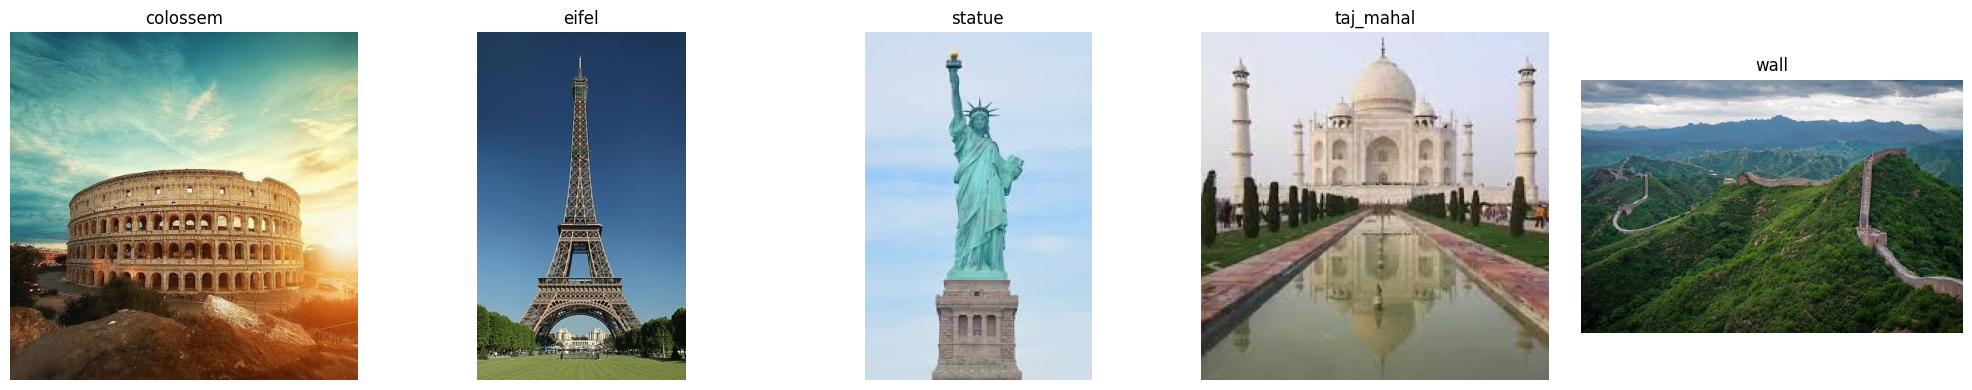

In [ ]:

valid_landmarks = [
    (name, images[0])
    for name, images in landmark_images.items()
    if images
]

fig, axes = plt.subplots(
    1, len(valid_landmarks),
    figsize=(4 * len(valid_landmarks), 4),
    squeeze=False
)

for ax, (landmark, image_path) in zip(axes[0], valid_landmarks):
    image = cv2.imread(str(image_path))

    if image is None:
        ax.set_title(f"{landmark}\nLoad error")
        ax.axis("off")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.set_title(landmark)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import cv2
import numpy as np
import time

# Create SIFT detector
sift = cv2.SIFT_create()

# Store each image's keypoints and descriptors
sift_database = []

start_time = time.time()

for landmark, image_paths in landmark_images.items():
    for image_path in image_paths:

        # Load image in grayscale
        gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

        if gray is None:
            print("Could not load:", image_path)
            continue

        # Detect keypoints and extract descriptors
        keypoints, descriptors = sift.detectAndCompute(gray, None)

        if descriptors is None or len(keypoints) == 0:
            print("No SIFT features found:", image_path)
            continue

        sift_database.append({
            "landmark": landmark,
            "image_path": str(image_path),
            "image_shape": gray.shape,
            "keypoints": keypoints,
            "descriptors": descriptors
        })

elapsed = time.time() - start_time

print("SIFT DATABASE CREATED")
print("-" * 35)
print("Reference images processed:", len(sift_database))
print("Landmarks:", len(landmark_images))
print(f"Extraction time: {elapsed:.2f} seconds")


SIFT DATABASE CREATED
-----------------------------------
Reference images processed: 25
Landmarks: 6
Extraction time: 2.90 seconds


In [ ]:

for item in sift_database:
    print(
        f"Landmark: {item['landmark']:20s} | "
        f"Keypoints: {len(item['keypoints']):4d} | "
        f"Image: {item['image_path']}"
    )


Landmark: colossem             | Keypoints:  836 | Image: drive/MyDrive/image_dataset/colossem/colossem_1.jpg
Landmark: colossem             | Keypoints: 1769 | Image: drive/MyDrive/image_dataset/colossem/colossem_2.jpg
Landmark: colossem             | Keypoints: 1879 | Image: drive/MyDrive/image_dataset/colossem/colossem_4.jpg
Landmark: colossem             | Keypoints: 3900 | Image: drive/MyDrive/image_dataset/colossem/colossem_3.jpg
Landmark: colossem             | Keypoints: 2549 | Image: drive/MyDrive/image_dataset/colossem/colossem_5.jpg
Landmark: eifel                | Keypoints:  652 | Image: drive/MyDrive/image_dataset/eifel/eifel_1.jpg
Landmark: eifel                | Keypoints: 2493 | Image: drive/MyDrive/image_dataset/eifel/eifel_2.jpg
Landmark: eifel                | Keypoints: 2457 | Image: drive/MyDrive/image_dataset/eifel/eifel_3.jpg
Landmark: eifel                | Keypoints: 1210 | Image: drive/MyDrive/image_dataset/eifel/eifel_4.jpg
Landmark: eifel                | K

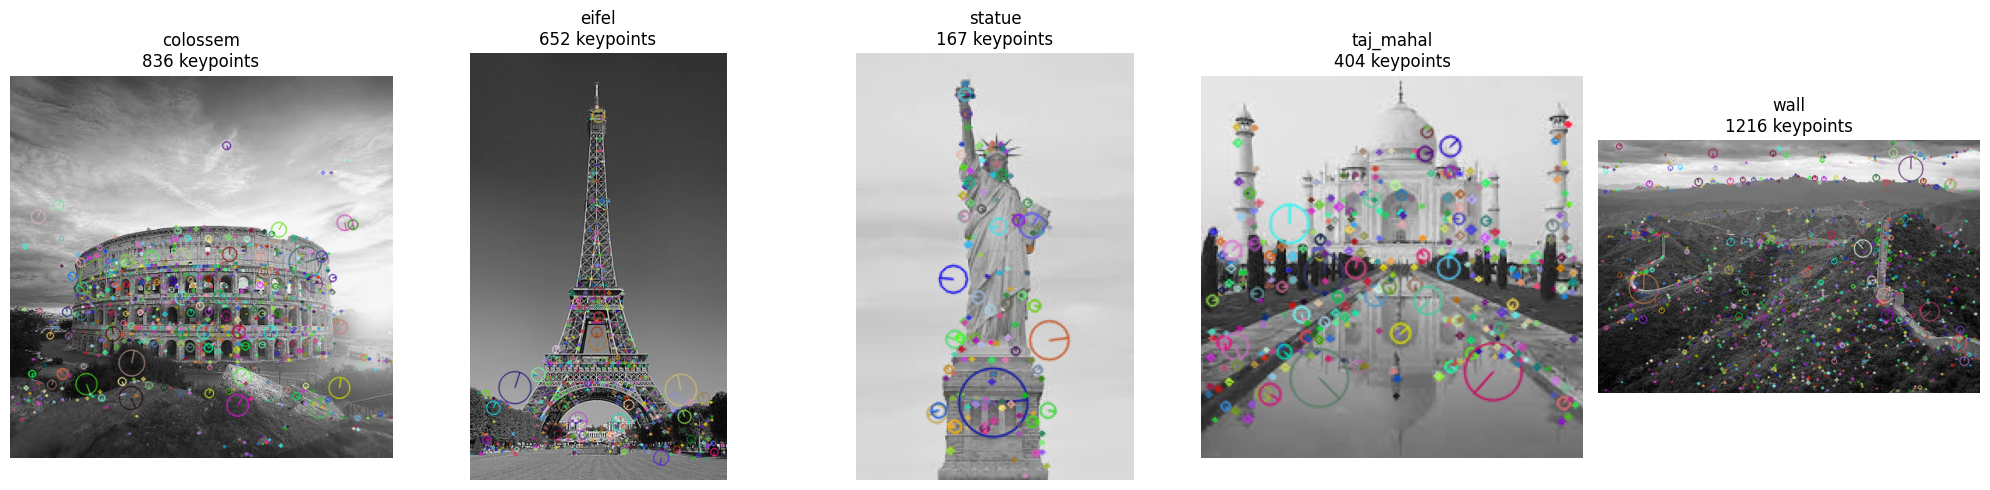

In [ ]:

# Display the first reference image for each landmark
shown = set()
examples = []

for item in sift_database:
    if item["landmark"] not in shown:
        examples.append(item)
        shown.add(item["landmark"])

fig, axes = plt.subplots(
    1, len(examples),
    figsize=(4 * len(examples), 5),
    squeeze=False
)

for ax, item in zip(axes[0], examples):
    gray = cv2.imread(
        item["image_path"],
        cv2.IMREAD_GRAYSCALE
    )

    keypoint_image = cv2.drawKeypoints(
        gray,
        item["keypoints"],
        None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    ax.imshow(keypoint_image, cmap="gray")
    ax.set_title(
        f"{item['landmark']}\n"
        f"{len(item['keypoints'])} keypoints"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Select the first image of a landmark for testing
query_path = landmark_images["eifel"][0]

print("Query image:", query_path)


Query image: drive/MyDrive/image_dataset/eifel/eifel_1.jpg


In [ ]:

def process_query(image_path):
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        raise ValueError(f"Could not load query image: {image_path}")

    keypoints, descriptors = sift.detectAndCompute(gray, None)

    print("QUERY IMAGE DETAILS")
    print("-" * 30)
    print("Image dimensions:", gray.shape)
    print("Keypoints detected:", len(keypoints))
    print(
        "Descriptor shape:",
        descriptors.shape if descriptors is not None else None
    )

    return gray, keypoints, descriptors


query_gray, query_keypoints, query_descriptors = process_query(query_path)


QUERY IMAGE DETAILS
------------------------------
Image dimensions: (550, 330)
Keypoints detected: 652
Descriptor shape: (652, 128)


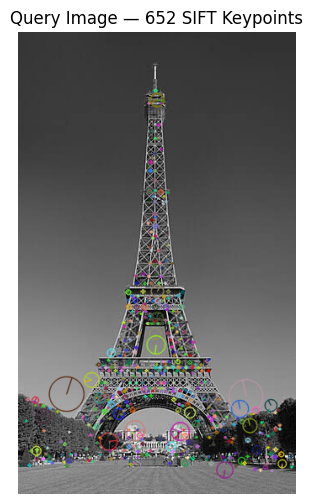

In [ ]:

query_keypoint_image = cv2.drawKeypoints(
    query_gray,
    query_keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(8, 6))
plt.imshow(query_keypoint_image, cmap="gray")
plt.title(f"Query Image — {len(query_keypoints)} SIFT Keypoints")
plt.axis("off")
plt.show()


In [ ]:

# SIFT descriptors use 128-dimensional floating-point vectors.
# NORM_L2 calculates their Euclidean distance.
bf = cv2.BFMatcher(cv2.NORM_L2)

def match_descriptors(query_descriptors, reference_descriptors):
    if query_descriptors is None or reference_descriptors is None:
        return []

    if len(query_descriptors) < 2 or len(reference_descriptors) < 2:
        return []

    # Find two nearest reference descriptors for each query descriptor
    knn_matches = bf.knnMatch(
        query_descriptors,
        reference_descriptors,
        k=2
    )

    # Lowe's ratio test
    good_matches = []

    for pair in knn_matches:
        if len(pair) == 2:
            first, second = pair

            if first.distance < 0.75 * second.distance:
                good_matches.append(first)

    return good_matches


In [ ]:

def recognize_landmark(
    query_gray,
    query_keypoints,
    query_descriptors,
    min_matches=12
):
    results = []

    for item in sift_database:
        good_matches = match_descriptors(
            query_descriptors,
            item["descriptors"]
        )

        results.append({
            "landmark": item["landmark"],
            "image_path": item["image_path"],
            "good_matches": good_matches,
            "match_count": len(good_matches),
            "reference": item
        })

    # Rank reference images by reliable match count
    results.sort(
        key=lambda result: result["match_count"],
        reverse=True
    )

    if not results:
        print("REJECTED: No reference images available.")
        return None, results

    best = results[0]

    if best["match_count"] < min_matches:
        print("LANDMARK RECOGNITION RESULT")
        print("-" * 35)
        print("Prediction: UNKNOWN LANDMARK")
        print("Reliable matches:", best["match_count"])
        print("Decision: REJECTED")
        return None, results

    print("LANDMARK RECOGNITION RESULT")
    print("-" * 35)
    print("Predicted landmark:", best["landmark"])
    print("Reference image:", best["image_path"])
    print("Reliable matches:", best["match_count"])
    print("Decision: CANDIDATE — geometric verification required")

    print("\nTop candidates:")
    for result in results[:5]:
        print(
            f"{result['landmark']:20s} "
            f"{result['match_count']} matches"
        )

    return best, results


In [ ]:

best_match, match_results = recognize_landmark(
    query_gray,
    query_keypoints,
    query_descriptors,
    min_matches=12
)


LANDMARK RECOGNITION RESULT
-----------------------------------
Predicted landmark: eifel
Reference image: drive/MyDrive/image_dataset/eifel/eifel_1.jpg
Reliable matches: 652
Decision: CANDIDATE — geometric verification required

Top candidates:
eifel                652 matches
eifel                13 matches
eifel                7 matches
taj_mahal            7 matches
taj_mahal            7 matches


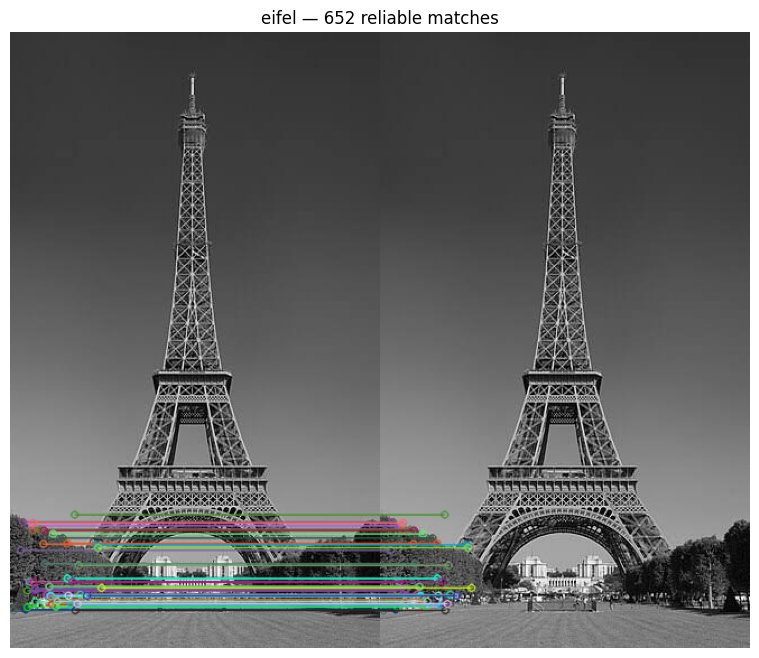

In [ ]:

if best_match is not None:
    reference = best_match["reference"]

    reference_gray = cv2.imread(
        reference["image_path"],
        cv2.IMREAD_GRAYSCALE
    )

    match_visualization = cv2.drawMatches(
        reference_gray,
        reference["keypoints"],
        query_gray,
        query_keypoints,
        best_match["good_matches"][:50],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(16, 8))
    plt.imshow(match_visualization, cmap="gray")
    plt.title(
        f"{best_match['landmark']} — "
        f"{best_match['match_count']} reliable matches"
    )
    plt.axis("off")
    plt.show()


In [ ]:

def localize_landmark(query_gray, query_keypoints, best_match,
                      min_matches=12, min_inliers=10):
    if best_match is None:
        print("Localization skipped: landmark was rejected.")
        return None

    reference = best_match["reference"]
    good_matches = best_match["good_matches"]

    if len(good_matches) < min_matches:
        print("Localization failed: insufficient reliable matches.")
        return None

    # Corresponding points in reference and query images
    src_pts = np.float32([
        reference["keypoints"][m.queryIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    dst_pts = np.float32([
        query_keypoints[m.trainIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    # Estimate geometric transformation with RANSAC
    H, mask = cv2.findHomography(
        src_pts,
        dst_pts,
        cv2.RANSAC,
        5.0
    )

    if H is None or mask is None:
        print("Localization failed: homography could not be estimated.")
        return None

    inlier_count = int(mask.ravel().sum())
    inlier_ratio = inlier_count / len(good_matches)

    print("Geometric verification")
    print("-" * 35)
    print("Reliable matches:", len(good_matches))
    print("RANSAC inliers:", inlier_count)
    print(f"Inlier ratio: {inlier_ratio:.2%}")

    if inlier_count < min_inliers or inlier_ratio < 0.35:
        print("Localization rejected: geometric evidence is weak.")
        return None

    # Reference image corners
    h, w = reference["image_shape"]

    corners = np.float32([
        [0, 0],
        [w - 1, 0],
        [w - 1, h - 1],
        [0, h - 1]
    ]).reshape(-1, 1, 2)

    projected_corners = cv2.perspectiveTransform(corners, H)

    # Reject polygons with non-finite coordinates
    if not np.isfinite(projected_corners).all():
        print("Localization rejected: invalid projected coordinates.")
        return None

    qh, qw = query_gray.shape

    polygon = projected_corners.reshape(-1, 2)

    # Reject degenerate or implausibly large polygons
    area = abs(cv2.contourArea(polygon.astype(np.float32)))
    if area < 100 or area > 4 * qh * qw:
        print("Localization rejected: polygon geometry is implausible.")
        return None

    # Draw the projected reference-image boundary
    output = cv2.cvtColor(query_gray, cv2.COLOR_GRAY2BGR)

    cv2.polylines(
        output,
        [np.int32(projected_corners)],
        isClosed=True,
        color=(0, 255, 0),
        thickness=3
    )

    return output


Geometric verification
-----------------------------------
Reliable matches: 652
RANSAC inliers: 652
Inlier ratio: 100.00%


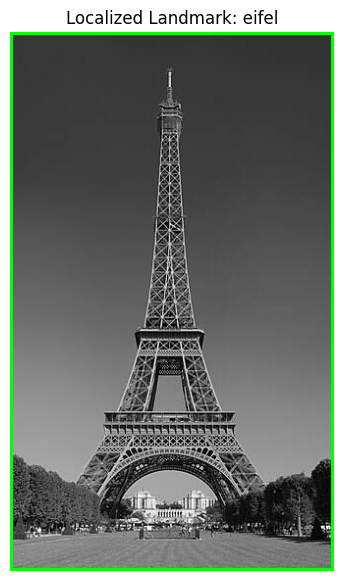

In [ ]:

localized_image = localize_landmark(
    query_gray,
    query_keypoints,
    best_match
)

if localized_image is not None:
    plt.figure(figsize=(9, 7))
    plt.imshow(cv2.cvtColor(localized_image, cv2.COLOR_BGR2RGB))
    plt.title(f"Localized Landmark: {best_match['landmark']}")
    plt.axis("off")
    plt.show()


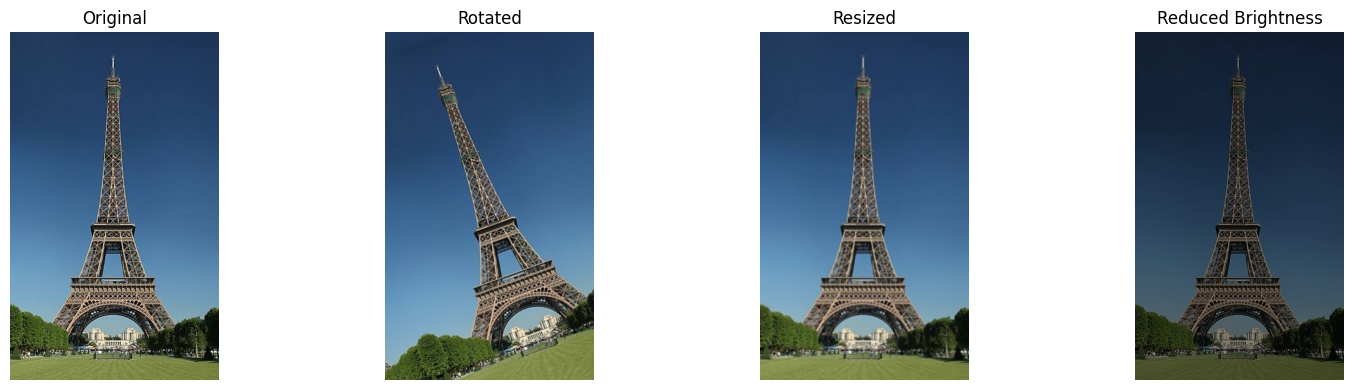

In [ ]:

def make_test_images(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not load image: {image_path}")

    h, w = image.shape[:2]

    # Rotation
    rotation_matrix = cv2.getRotationMatrix2D(
        (w // 2, h // 2), 20, 1.0
    )
    rotated = cv2.warpAffine(
        image, rotation_matrix, (w, h),
        borderMode=cv2.BORDER_REFLECT
    )

    # Resize to 70%, then restore original dimensions
    smaller = cv2.resize(
        image, None, fx=0.7, fy=0.7,
        interpolation=cv2.INTER_AREA
    )
    resized = cv2.resize(
        smaller, (w, h),
        interpolation=cv2.INTER_LINEAR
    )

    # Reduced brightness
    darker = cv2.convertScaleAbs(image, alpha=0.55, beta=0)

    return {
        "Original": image,
        "Rotated": rotated,
        "Resized": resized,
        "Reduced Brightness": darker
    }


test_images = make_test_images(query_path)

fig, axes = plt.subplots(1, len(test_images), figsize=(16, 4))

for ax, (name, image) in zip(axes, test_images.items()):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import time
import pandas as pd


def evaluate_query_image(image, test_name, expected_landmark=None):
    start_time = time.perf_counter()

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    keypoints, descriptors = sift.detectAndCompute(gray, None)

    best, results = recognize_landmark(
        gray,
        keypoints,
        descriptors,
        min_matches=12
    )

    reliable_matches = best["match_count"] if best else 0
    predicted = best["landmark"] if best else "Unknown"

    inliers = 0
    recognized = False

    if best is not None:
        reference = best["reference"]
        matches = best["good_matches"]

        # Require enough matches and valid keypoint indices
        valid_matches = [
            m for m in matches
            if m.queryIdx < len(keypoints)
            and m.trainIdx < len(reference["keypoints"])
        ]

        if len(valid_matches) >= 12:
            # findHomography maps reference points to query points
            src = np.float32([
                reference["keypoints"][m.trainIdx].pt
                for m in valid_matches
            ]).reshape(-1, 1, 2)

            dst = np.float32([
                keypoints[m.queryIdx].pt
                for m in valid_matches
            ]).reshape(-1, 1, 2)

            H, mask = cv2.findHomography(
                src, dst, cv2.RANSAC, 5.0
            )

            if H is not None and mask is not None:
                inliers = int(mask.ravel().sum())
                ratio = inliers / len(valid_matches)

                recognized = (
                    inliers >= 10
                    and ratio >= 0.35
                )

    if not recognized:
        predicted = "Unknown"

    elapsed = time.perf_counter() - start_time

    return {
        "Test": test_name,
        "Expected": expected_landmark or "Unknown",
        "Predicted": predicted,
        "Keypoints": len(keypoints),
        "Reliable Matches": reliable_matches,
        "RANSAC Inliers": inliers,
        "Decision": "Recognized" if recognized else "Rejected",
        "Correct": (
            predicted == expected_landmark
            if expected_landmark is not None
            else not recognized
        ),
        "Time (seconds)": round(elapsed, 4)
    }


In [ ]:

# The original query comes from this landmark folder.
expected = Path(query_path).parent.name

evaluation_results = []

for test_name, image in test_images.items():
    result = evaluate_query_image(
        image,
        test_name,
        expected_landmark=expected
    )
    evaluation_results.append(result)

    print(
        f"{test_name}: {result['Predicted']} | "
        f"{result['Decision']} | "
        f"Matches: {result['Reliable Matches']} | "
        f"Inliers: {result['RANSAC Inliers']}"
    )

evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df)


LANDMARK RECOGNITION RESULT
-----------------------------------
Predicted landmark: eifel
Reference image: drive/MyDrive/image_dataset/eifel/eifel_1.jpg
Reliable matches: 631
Decision: CANDIDATE — geometric verification required

Top candidates:
eifel                631 matches
eifel                12 matches
eifel                6 matches
taj_mahal            6 matches
taj_mahal            6 matches
Original: eifel | Recognized | Matches: 631 | Inliers: 631
LANDMARK RECOGNITION RESULT
-----------------------------------
Predicted landmark: eifel
Reference image: drive/MyDrive/image_dataset/eifel/eifel_1.jpg
Reliable matches: 439
Decision: CANDIDATE — geometric verification required

Top candidates:
eifel                439 matches
eifel                25 matches
colossem             7 matches
eifel                6 matches
statue               6 matches
Rotated: eifel | Recognized | Matches: 439 | Inliers: 415
LANDMARK RECOGNITION RESULT
-----------------------------------
Predicted l

,Test,Expected,Predicted,Keypoints,Reliable Matches,RANSAC Inliers,Decision,Correct,Time (seconds)
0,Original,eifel,eifel,648,631,631,Recognized,True,0.7810
1,Rotated,eifel,eifel,827,439,415,Recognized,True,0.9694
2,Resized,eifel,eifel,1253,395,377,Recognized,True,1.5464
3,Reduced Brightness,eifel,eifel,568,545,544,Recognized,True,0.6719


In [ ]:

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df[
        [
            "Test",
            "Expected",
            "Predicted",
            "Keypoints",
            "Reliable Matches",
            "RANSAC Inliers",
            "Decision",
            "Correct",
            "Time (seconds)"
        ]
    ]
)


,Test,Expected,Predicted,Keypoints,Reliable Matches,RANSAC Inliers,Decision,Correct,Time (seconds)
0,Original,eifel,eifel,648,631,631,Recognized,True,0.7810
1,Rotated,eifel,eifel,827,439,415,Recognized,True,0.9694
2,Resized,eifel,eifel,1253,395,377,Recognized,True,1.5464
3,Reduced Brightness,eifel,eifel,568,545,544,Recognized,True,0.6719
